# Aula 02 — Assistente Virtual em Tempo Real: por que a atenção custa caro?

**Disciplina: Engenharia de Machine Learning — FIAP PósTech**

---

## 🎯 Objetivo da aula

Nesta versão simplificada e consolidada em **um único notebook**, vamos entender, na prática, **um** conceito central de performance em NLP:

> **A complexidade quadrática O(n²) do mecanismo de atenção dos Transformers** e por que ela é o principal gargalo de latência quando um assistente virtual precisa responder em tempo real.

Vamos:

1. Entender o problema do assistente virtual de voz.
2. Explicar de forma simples o que é a atenção e por que ela é O(n²).
3. Implementar uma atenção mínima em NumPy.
4. Medir na prática como a latência cresce com o tamanho da pergunta.
5. Interpretar os resultados e discutir alternativas eficientes.
6. Concluir com os principais aprendizados.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Álgebra linear / atenção |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy` e `matplotlib`. Não requer GPU, internet ou datasets externos.

### 2. Instalação das dependências

Escolha **uma** das opções abaixo.

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 02_desafios_performance_nlp_audio
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError: No module named 'numpy'`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.


## 1. Contexto do problema e motivação

Imagine um **assistente virtual de compras por voz**. O usuário pergunta em voz alta:

> 🗣️ *"Quais tênis de corrida leves custam menos de 500 reais?"*

Para responder **em poucos segundos**, o sistema executa um pipeline:

1. **ASR (Automatic Speech Recognition)** — transforma o áudio da voz em texto.
2. **NLP / LLM** — interpreta a pergunta em texto (é aqui que entra a atenção dos Transformers).
3. **Busca** — encontra os produtos relevantes.
4. **TTS (Text-to-Speech)** — converte a resposta em fala.

```
🎤 Voz → [ASR] → texto → [NLP/LLM] → intenção → [Busca] → resposta → [TTS] → 🔊 Fala
```

Cada etapa consome tempo, mas a etapa de **NLP/LLM** costuma ser o maior gargalo, porque o modelo de linguagem usa o **mecanismo de atenção**, cujo custo **cresce ao quadrado** em relação ao tamanho do texto. Quanto maior a pergunta (ou o contexto), mais lenta fica a resposta — e o usuário percebe o atraso.

**Nesta aula focamos exatamente nesse gargalo.**

In [3]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar a proxima celula.
# %pip install numpy matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, matplotlib
    print("numpy:", numpy.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy matplotlib' acima e rode esta celula novamente.")


Python: 3.13.14
numpy: 2.5.0
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


In [4]:
# Bibliotecas usadas (apenas numpy e matplotlib para manter simples e executavel)
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print("Ambiente pronto.")

Ambiente pronto.


## 2. Explicação simples: o que é atenção e por que é O(n²)?

Quando o modelo de linguagem lê a pergunta, ele primeiro a divide em **tokens** (pedaços de palavras). Chamamos de `n` o número de tokens.

No mecanismo de **self-attention**, cada token "olha" para **todos os outros tokens** para entender o contexto. A fórmula é:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

O ponto-chave é a matriz $QK^T$: ela tem tamanho $n \times n$, ou seja, compara **cada token com cada token**.

- 10 tokens → 10 × 10 = **100** comparações
- 100 tokens → 100 × 100 = **10.000** comparações
- 1.000 tokens → 1.000 × 1.000 = **1.000.000** de comparações

Dobrar o tamanho da pergunta **quadruplica** o trabalho. Isso é a **complexidade quadrática O(n²)**, e é por isso que perguntas longas (ou muito contexto) deixam o assistente mais lento. (Vaswani et al., 2017)

## 3. Exemplo prático: uma atenção mínima em NumPy

Vamos implementar a atenção de forma bem simples para ver o custo aparecendo no código.
Cada token é representado por um vetor de tamanho `d` (a "dimensão do modelo").

In [5]:
def softmax(x, axis=-1):
    """Softmax numericamente estavel."""
    x = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)


def self_attention(x):
    """Self-attention simplificada (scaled dot-product).

    x: matriz (n, d) com n tokens de dimensao d.
    Retorna a saida (n, d) e a matriz de atencao (n, n).
    """
    n, d = x.shape
    # Para simplificar, usamos os proprios tokens como Q, K e V
    Q = K = V = x
    scores = Q @ K.T / np.sqrt(d)   # <-- matriz n x n (aqui mora o custo O(n^2))
    attn = softmax(scores, axis=-1)
    output = attn @ V
    return output, attn


# Exemplo com uma frase curta de 6 tokens e dimensao 8
tokens = np.random.randn(6, 8)
out, attn = self_attention(tokens)

print("Tokens de entrada:", tokens.shape)
print("Matriz de atencao:", attn.shape, "<- repare: n x n")
print("Saida:", out.shape)

Tokens de entrada: (6, 8)
Matriz de atencao: (6, 6) <- repare: n x n
Saida: (6, 8)


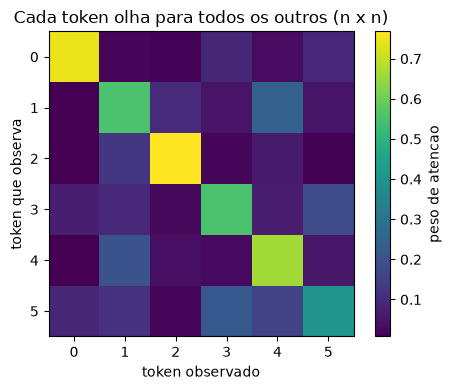

In [6]:
# Visualizando a matriz de atencao: cada token (linha) olhando para todos (colunas)
plt.figure(figsize=(5, 4))
plt.imshow(attn, cmap="viridis")
plt.colorbar(label="peso de atencao")
plt.title("Cada token olha para todos os outros (n x n)")
plt.xlabel("token observado")
plt.ylabel("token que observa")
plt.tight_layout()
plt.show()

## 4. Hands-on guiado: medindo a latência conforme a pergunta cresce

Agora o experimento central. Vamos simular perguntas de tamanhos diferentes (em número de tokens) e **medir o tempo** que a atenção leva. A hipótese: o tempo cresce de forma **quadrática**, não linear.

> 💡 Relação com o caso de uso: uma pergunta curta como *"tênis barato?"* tem poucos tokens; já *"quais tênis de corrida leves, confortáveis e com boa amortização custam menos de 500 reais na loja?"* tem muitos. O segundo caso custa **muito** mais tempo de atenção.

In [7]:
d = 64  # dimensao do modelo (fixa)
seq_lengths = [16, 32, 64, 128, 256, 512, 1024]  # tamanhos de "pergunta" em tokens

tempos_ms = []
for n in seq_lengths:
    x = np.random.randn(n, d)
    # media de algumas execucoes para medir com mais estabilidade
    inicio = time.perf_counter()
    for _ in range(5):
        self_attention(x)
    fim = time.perf_counter()
    tempo_medio = (fim - inicio) / 5 * 1000  # em milissegundos
    tempos_ms.append(tempo_medio)
    print(f"n = {n:>5} tokens  ->  {tempo_medio:8.3f} ms")

n =    16 tokens  ->     0.042 ms
n =    32 tokens  ->     0.034 ms
n =    64 tokens  ->     0.052 ms
n =   128 tokens  ->     0.350 ms
n =   256 tokens  ->     0.815 ms
n =   512 tokens  ->     4.696 ms
n =  1024 tokens  ->    19.179 ms


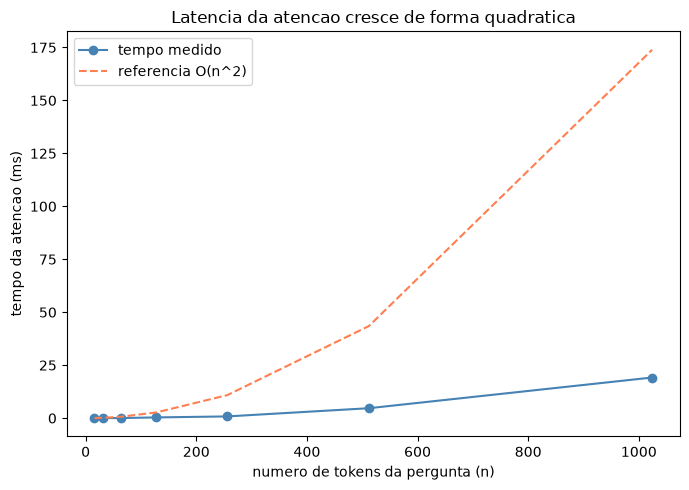

In [8]:
# Comparando o tempo medido com uma referencia teorica O(n^2)
seq = np.array(seq_lengths)
tempos = np.array(tempos_ms)

# curva teorica n^2 reescalada para o mesmo ponto de partida
ref_quadratica = (seq / seq[0]) ** 2 * tempos[0]

plt.figure(figsize=(7, 5))
plt.plot(seq, tempos, "o-", label="tempo medido", color="steelblue")
plt.plot(seq, ref_quadratica, "--", label="referencia O(n^2)", color="coral")
plt.xlabel("numero de tokens da pergunta (n)")
plt.ylabel("tempo da atencao (ms)")
plt.title("Latencia da atencao cresce de forma quadratica")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Resultados e interpretação

Vamos olhar o que acontece com o tempo quando **dobramos** o tamanho da pergunta. Se a complexidade fosse linear, o tempo dobraria (fator ~2×). Se for quadrática, ele **quadruplica** (fator ~4×).

In [9]:
print("Fator de aumento do tempo ao dobrar n:\n")
for i in range(1, len(seq_lengths)):
    fator = tempos_ms[i] / tempos_ms[i - 1]
    print(f"{seq_lengths[i-1]:>5} -> {seq_lengths[i]:>5} tokens : tempo x{fator:.1f}")

print("\nComplexidade linear dobraria (~2x). Quadratica quadruplica (~4x).")
print("Os fatores proximos de 4x confirmam o comportamento O(n^2).")

Fator de aumento do tempo ao dobrar n:

   16 ->    32 tokens : tempo x0.8
   32 ->    64 tokens : tempo x1.5
   64 ->   128 tokens : tempo x6.7
  128 ->   256 tokens : tempo x2.3
  256 ->   512 tokens : tempo x5.8
  512 ->  1024 tokens : tempo x4.1

Complexidade linear dobraria (~2x). Quadratica quadruplica (~4x).
Os fatores proximos de 4x confirmam o comportamento O(n^2).


### O que isso significa para o assistente virtual?

- Perguntas **curtas e diretas** são processadas rápido → boa experiência.
- Perguntas **longas** ou com muito **contexto** (histórico da conversa, descrição de produtos) fazem o tempo de atenção explodir → o usuário sente o atraso.
- Como o pipeline (ASR → NLP → busca → TTS) precisa caber em **poucos segundos**, o gargalo O(n²) da atenção precisa ser controlado.

### Como resolver? (alternativas eficientes)

Existem técnicas que reduzem esse custo — que aqui apenas mencionamos para dar direção:

| Técnica | Ideia central | Ganho |
|---|---|---|
| **Sparse Attention** | cada token olha só para alguns tokens, não todos | menos comparações |
| **Linear Attention** | reorganiza a matemática para custo O(n) | escala linear |
| **Flash Attention** | otimiza o uso da memória da GPU (IO-awareness) | 2–4× mais rápido |

Todas atacam o mesmo problema que medimos: fazer a atenção crescer **menos** que O(n²).

## 6. Conclusão e próximos passos

**Principais aprendizados:**

1. Em um assistente virtual de voz, o pipeline **ASR → NLP → busca → TTS** precisa responder em poucos segundos.
2. O maior gargalo costuma estar no **modelo de linguagem (NLP)**, por causa do mecanismo de **atenção**.
3. A atenção compara cada token com todos os outros → matriz `n × n` → **complexidade O(n²)**.
4. Medimos na prática: **dobrar** o tamanho da pergunta **quadruplica** o tempo.
5. Por isso, perguntas curtas respondem rápido, e alternativas como **Sparse / Linear / Flash Attention** existem para reduzir esse custo.

**Próximos passos sugeridos:**

- Repetir o experimento variando a dimensão `d` do modelo e observar o efeito.
- Implementar uma versão simples de *sparse attention* (cada token olha só para os vizinhos) e comparar a latência.
- Explorar o pré-processamento de **áudio** (espectrogramas Mel / MFCC) usado na etapa de ASR.

---

*Material da Aula 02 — Engenharia de Machine Learning — FIAP PósTech.*